# Tarea 4: Introducción a Series de Tiempo
**Business Intelligence · Universidad del Istmo de Guatemala**

Autor: José Sierra

Este notebook corre de principio a fin a partir del archivo original `Online Retail.xlsx` y
reproduce todas las cifras, tablas y figuras del documento. Las figuras se guardan en
`figuras/`, las tablas en `tablas/` y las cifras citadas en el texto en `tablas/cifras.tex`.

**Semillas:** Parte 0 usa una semilla distinta por escenario (`SEMILLAS` abajo);
la validación cruzada de la Parte 5 usa las semillas 0 a 9; la Parte 6 usa
`numpy.random.default_rng(2026)` como pide el enunciado.

In [1]:
import os
import sys
import glob
import subprocess

REPO_URL = "https://github.com/josesierra4512/Tarea4_Sierra.git"

try:
    import google.colab  # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB and not os.path.exists("ts_utils.py"):
    if not os.path.exists("/content/repo"):
        r = subprocess.run(["git", "clone", REPO_URL, "/content/repo"], capture_output=True, text=True)
        print(r.stdout, r.stderr)
        if r.returncode != 0:
            raise RuntimeError("No se pudo clonar el repo: revisa REPO_URL y que el repo sea público.")
    encontrados = glob.glob("/content/repo/**/ts_utils.py", recursive=True)
    if not encontrados:
        raise FileNotFoundError("El repo no tiene ts_utils.py: súbelo a GitHub junto con limpiar.py.")
    os.chdir(os.path.dirname(encontrados[0]))

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("Carpeta de trabajo:", os.getcwd())
print("ts_utils.py:", os.path.exists("ts_utils.py"), "| limpiar.py:", os.path.exists("limpiar.py"))

Carpeta de trabajo: /content/repo/Tarea4_Sierra
ts_utils.py: True | limpiar.py: True


## Parte 0: Procesos simulados

Las funciones `acf`, `ljung_box` y `ar1_ols` están en `ts_utils.py`, implementadas con numpy.
Primero verificamos `ljung_box` contra `statsmodels` sobre un ruido blanco.

In [3]:
N, REPS = 300, 5000
PHIS = [0.0, 0.5, 0.9, 1.0]
SEMILLAS = {0.0: 1000, 0.5: 1050, 0.9: 1090, 1.0: 1100, "tendencia": 2001, "semanal": 2002}

try:
    from statsmodels.stats.diagnostic import acorr_ljungbox
    y_prueba = np.random.default_rng(7).normal(size=N)
    q_mio, p_mio = ljung_box(y_prueba, 10)
    sm = acorr_ljungbox(y_prueba, lags=[10])
    print(f"Q(10) propio = {q_mio:.6f}, p = {p_mio:.6f}")
    print(f"Q(10) statsmodels = {sm['lb_stat'].iloc[0]:.6f}, p = {sm['lb_pvalue'].iloc[0]:.6f}")
except ImportError:
    print("statsmodels no está instalado; se omite la verificación.")

Q(10) propio = 10.753587, p = 0.377035
Q(10) statsmodels = 10.753587, p = 0.377035


### 0.2 Una realización de cada AR(1)

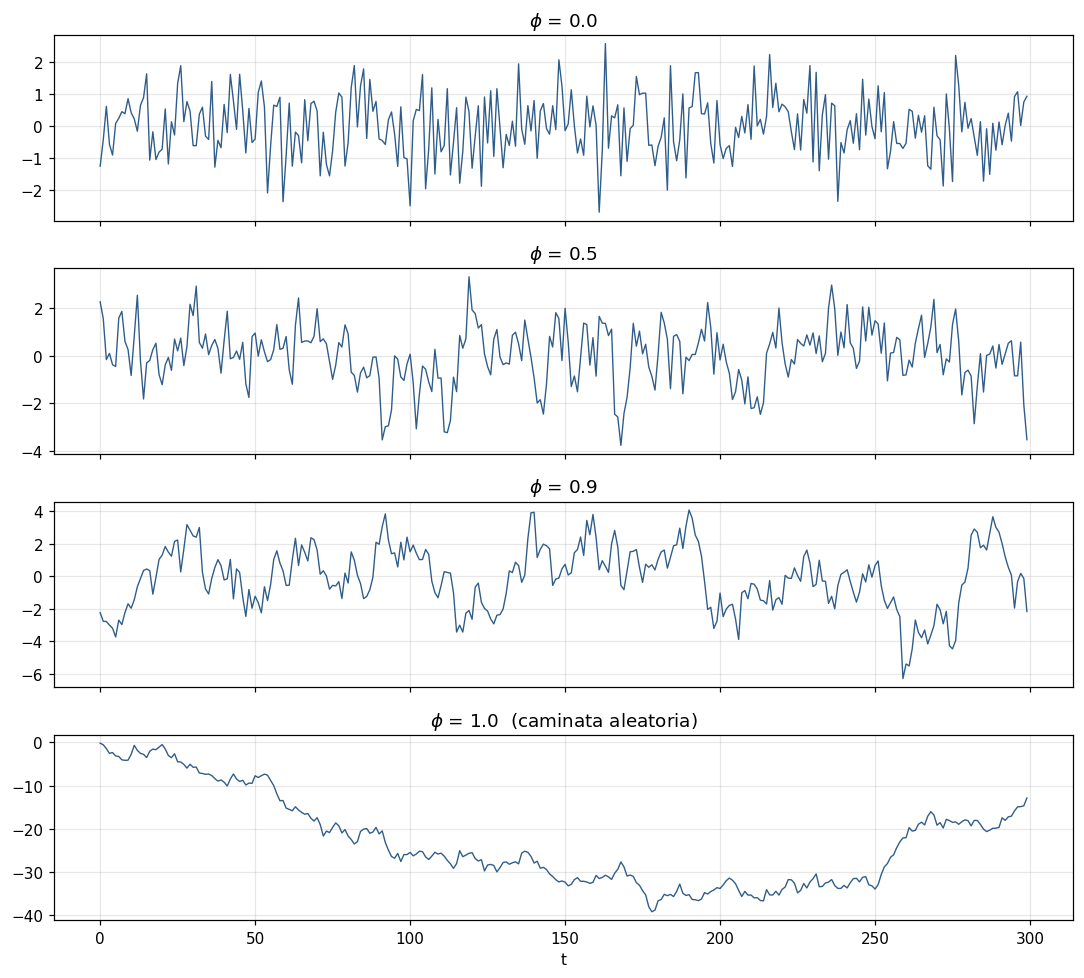

In [4]:
fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
for ax, phi in zip(axes, PHIS):
    y = simular_ar1(phi, n=N, reps=1, rng=np.random.default_rng(SEMILLAS[phi] + 7))[0]
    ax.plot(y, lw=0.9, color="#2F5D8A")
    ax.set_title(f"$\\phi$ = {phi}" + ("  (caminata aleatoria)" if phi == 1 else ""))
axes[-1].set_xlabel("t")
guardar_fig(fig, "p0_realizaciones")
plt.show()

### 0.2 Tabla de 5 000 réplicas por $\phi$
Para cada réplica calculamos $r_1$, $r_5$, si $|r_1| > 1.96/\sqrt{n}$ y el estimado OLS de $\phi$.
El error estándar de cada promedio es la desviación estándar entre réplicas dividida entre $\sqrt{5000}$;
para una proporción $p$ es $\sqrt{p(1-p)/5000}$.

In [5]:
def resumen_media(x):
    return x.mean(), x.std(ddof=1) / np.sqrt(len(x))


filas = []
sims = {}
for phi in PHIS:
    Y = simular_ar1(phi, n=N, reps=REPS, rng=np.random.default_rng(SEMILLAS[phi]))
    sims[phi] = Y
    r = acf(Y, 10)
    _, phi_hat = ar1_ols(Y)
    rech = (np.abs(r[:, 0]) > bandas(N)).astype(float)
    m1, e1 = resumen_media(r[:, 0])
    m5, e5 = resumen_media(r[:, 4])
    mr, er = resumen_media(rech)
    mp, ep = resumen_media(phi_hat)
    filas.append({"phi": phi, "media r1": m1, "EE r1": e1, "media r5": m5, "EE r5": e5,
                  "teórico phi^5": phi ** 5, "tasa rechazo r1": mr, "EE rechazo": er,
                  "media phi OLS": mp, "EE phi OLS": ep, "sesgo phi OLS": mp - phi})
tabla_02 = pd.DataFrame(filas)
guardar_tabla(tabla_02, "p0_tabla02", formatos={"phi": "{:.1f}"})
tabla_02.round(4)

,phi,media r1,EE r1,media r5,EE r5,teórico phi^5,tasa rechazo r1,EE rechazo,media phi OLS,EE phi OLS,sesgo phi OLS
0,0.0,-0.0033,0.0008,-0.0035,0.0008,0.0000,0.0486,0.003,-0.0033,0.0008,-0.0033
1,0.5,0.4911,0.0007,0.0200,0.0010,0.0312,1.0000,0.000,0.4927,0.0007,-0.0073
2,0.9,0.8841,0.0004,0.5335,0.0014,0.5905,1.0000,0.000,0.8874,0.0004,-0.0126
3,1.0,0.9758,0.0002,0.8834,0.0009,1.0000,1.0000,0.000,0.9823,0.0002,-0.0177


In [6]:
for fila in filas:
    tag = {0.0: "Cero", 0.5: "Medio", 0.9: "Nueve", 1.0: "Uno"}[fila["phi"]]
    cifra(f"rechazoPhi{tag}", 100 * fila["tasa rechazo r1"], "{:.2f}%")
    cifra(f"rCincoPhi{tag}", fila["media r5"], "{:.3f}")
    cifra(f"phiOLSPhi{tag}", fila["media phi OLS"], "{:.3f}")
    cifra(f"sesgoPhi{tag}", fila["sesgo phi OLS"], "{:.4f}")

# Sesgo teórico aproximado de Kendall para el OLS del AR(1) con intercepto: -(1+3 phi)/n
for phi in [0.0, 0.5, 0.9]:
    print(f"phi={phi}: sesgo de Kendall aprox. = {-(1 + 3 * phi) / N:.4f}")

phi=0.0: sesgo de Kendall aprox. = -0.0033
phi=0.5: sesgo de Kendall aprox. = -0.0083
phi=0.9: sesgo de Kendall aprox. = -0.0123


**¿Por qué el valor inicial no afecta a $r_k$ cuando $\phi=1$?** En una caminata aleatoria
$Y_t = Y_0 + \sum_{j\le t}\varepsilon_j$, así que el valor inicial suma la misma constante a
todas las observaciones. $r_k$ resta la media muestral antes de multiplicar, y esa constante
desaparece: $r_k$ es invariante a sumar una constante a toda la serie.

### 0.4 Dos procesos sin memoria pero con media cambiante

In [7]:
t = np.arange(1, N + 1)
medias = {
    "tendencia": 2 * t / N,
    "semanal": np.where(t % 7 == 6, -1.5, 0.25),
}
for nombre in medias:
    rng = np.random.default_rng(SEMILLAS[nombre])
    sims[nombre] = medias[nombre][None, :] + rng.normal(size=(REPS, N))

filas = []
for nombre in [0.0, "tendencia", "semanal"]:
    Y = sims[nombre]
    r = acf(Y, 10)
    rech = (np.abs(r[:, 0]) > bandas(N)).astype(float)
    m1, e1 = resumen_media(r[:, 0])
    m7, e7 = resumen_media(r[:, 6])
    mr, er = resumen_media(rech)
    filas.append({"proceso": "ruido blanco (phi=0)" if nombre == 0.0 else nombre,
                  "media r1": m1, "EE r1": e1, "media r7": m7, "EE r7": e7,
                  "tasa rechazo r1": mr, "EE rechazo": er})
tabla_04 = pd.DataFrame(filas)
guardar_tabla(tabla_04, "p0_tabla04")
tabla_04.round(4)

,proceso,media r1,EE r1,media r7,EE r7,tasa rechazo r1,EE rechazo
0,ruido blanco (phi=0),-0.0033,0.0008,-0.0028,0.0008,0.0486,0.0030
1,tendencia,0.2449,0.0008,0.2296,0.0008,0.9840,0.0018
2,semanal,-0.0474,0.0008,0.2648,0.0008,0.1090,0.0044


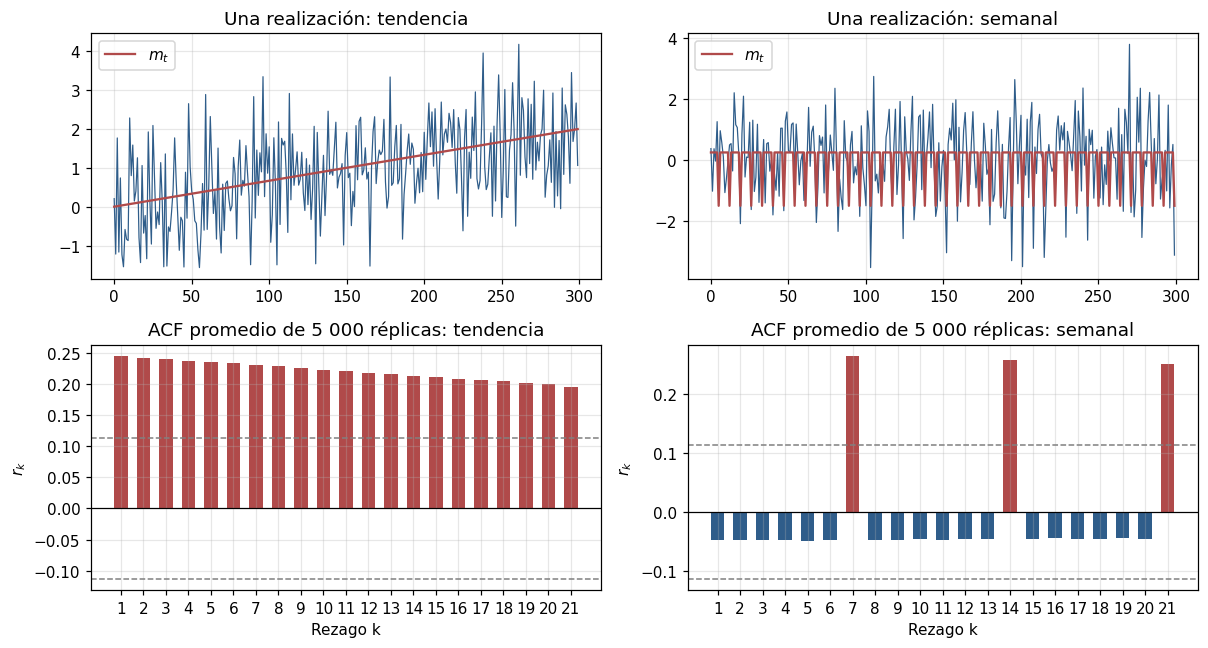

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for i, nombre in enumerate(["tendencia", "semanal"]):
    axes[0, i].plot(sims[nombre][0], lw=0.8, color="#2F5D8A")
    axes[0, i].plot(medias[nombre], color="#B04A4A", lw=1.5, label="$m_t$")
    axes[0, i].set_title(f"Una realización: {nombre}")
    axes[0, i].legend()
    graficar_acf(axes[1, i], acf(sims[nombre], 21).mean(axis=0), N,
                 f"ACF promedio de 5 000 réplicas: {nombre}")
guardar_fig(fig, "p0_dos_razones")
plt.show()

for fila in filas:
    tag = {"ruido blanco (phi=0)": "Ruido", "tendencia": "Tendencia", "semanal": "Semanal"}[fila["proceso"]]
    cifra(f"rechazoUno{tag}", 100 * fila["tasa rechazo r1"], "{:.2f}%")
    cifra(f"rUno{tag}", fila["media r1"], "{:.3f}")
    cifra(f"rSiete{tag}", fila["media r7"], "{:.3f}")

### 0.5 Ljung–Box con $m=10$ (y, como sugiere Tsay, $m \approx \log n$)

In [9]:
m_log = int(round(np.log(N)))
filas = []
for nombre in [0.0, "tendencia", "semanal"]:
    Y = sims[nombre]
    fila = {"proceso": "ruido blanco (phi=0)" if nombre == 0.0 else nombre}
    for m in [10, m_log]:
        _, p = ljung_box(Y, m)
        rech = (p < 0.05).astype(float)
        fila[f"rechazo LB m={m}"], fila[f"EE m={m}"] = resumen_media(rech)
    fila["rechazo r1 (de 0.4)"] = (np.abs(acf(Y, 1)[:, 0]) > bandas(N)).mean()
    filas.append(fila)
tabla_05 = pd.DataFrame(filas)
guardar_tabla(tabla_05, "p0_tabla05")
cifra("mLog", m_log, "{:d}")
for fila in filas:
    tag = {"ruido blanco (phi=0)": "Ruido", "tendencia": "Tendencia", "semanal": "Semanal"}[fila["proceso"]]
    cifra(f"lbDiez{tag}", 100 * fila["rechazo LB m=10"], "{:.2f}%")
    cifra(f"lbLog{tag}", 100 * fila[f"rechazo LB m={m_log}"], "{:.2f}%")
tabla_05.round(4)

,proceso,rechazo LB m=10,EE m=10,rechazo LB m=6,EE m=6,rechazo r1 (de 0.4)
0,ruido blanco (phi=0),0.051,0.0031,0.0508,0.0031,0.0486
1,tendencia,1.000,0.0000,1.0000,0.0000,0.9840
2,semanal,0.951,0.0031,0.1994,0.0057,0.1090


LOS DATOS


In [10]:
from limpiar import cargar, limpiar, normalizar, es_no_producto, es_cancelacion, CODIGOS_NO_PRODUCTO

RUTA_XLSX = Path("data/Online Retail.xlsx")
CACHE = Path("data/online_retail.pkl")
RUTA_XLSX.parent.mkdir(exist_ok=True)

if not RUTA_XLSX.exists() and not CACHE.exists():
    try:
        from google.colab import files
        print("Sube el archivo 'Online Retail.xlsx'")
        subido = files.upload()
        Path(next(iter(subido))).rename(RUTA_XLSX)
    except ImportError:
        raise FileNotFoundError("Coloca 'Online Retail.xlsx' dentro de la carpeta data/")

if CACHE.exists():
    crudo = pd.read_pickle(CACHE)
else:
    crudo = cargar(RUTA_XLSX)
    crudo.to_pickle(CACHE)

crudo["Monto"] = crudo["Quantity"] * crudo["UnitPrice"]
crudo.head()

Sube el archivo 'Online Retail.xlsx'


Saving Online Retail.xlsx to Online Retail.xlsx


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Monto
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


## Parte 1: Limpieza
### 1.1 Tamaño de la base

In [11]:
n_filas = len(crudo)
n_facturas = crudo["InvoiceNo"].nunique()
n_productos = crudo["StockCode"].nunique()
n_clientes = crudo["CustomerID"].nunique()
frac_sin_cliente = crudo["CustomerID"].isna().mean()

tabla_11 = pd.DataFrame({
    "medida": ["Filas", "Facturas distintas", "Productos (StockCode) distintos",
               "Clientes (CustomerID) distintos", "Fracción de filas sin CustomerID"],
    "valor": [f"{n_filas:,}", f"{n_facturas:,}", f"{n_productos:,}", f"{n_clientes:,}",
              f"{100 * frac_sin_cliente:.2f}%"],
})
guardar_tabla(tabla_11, "p1_tamano")
cifra("nFilas", n_filas, "{:,}"); cifra("nFacturas", n_facturas, "{:,}")
cifra("nProductos", n_productos, "{:,}"); cifra("nClientes", n_clientes, "{:,}")
cifra("fracSinCliente", 100 * frac_sin_cliente, "{:.2f}%")
print(f"Rango de fechas: {crudo['InvoiceDate'].min()} a {crudo['InvoiceDate'].max()}")
tabla_11

Rango de fechas: 2010-12-01 08:26:00 a 2011-12-09 12:50:00


,medida,valor
0,Filas,"541,909"
1,Facturas distintas,"25,900"
2,Productos (StockCode) distintos,"4,070"
3,Clientes (CustomerID) distintos,"4,372"
4,Fracción de filas sin CustomerID,24.93%


### 1.2 (a) Filas duplicadas exactas

In [12]:
dup = crudo.drop(columns="Monto").duplicated(keep="first")
print(f"Filas duplicadas exactas: {dup.sum():,} (monto £{crudo.loc[dup, 'Monto'].sum():,.2f})")
cifra("nDuplicados", int(dup.sum()), "{:,}")
crudo[crudo.drop(columns="Monto").duplicated(keep=False)].sort_values(["InvoiceNo", "StockCode"]).head(6)

Filas duplicadas exactas: 5,268 (monto £21,740.98)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Monto
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom,1.25
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom,1.25
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom,4.95
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom,4.95
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom,2.10
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom,2.10


### 1.2 (b) Facturas que no empiezan con un dígito

In [13]:
prefijo = crudo["InvoiceNo"].str.extract(r"^(\D*)")[0].fillna("")
resumen_prefijos = (crudo.assign(prefijo=prefijo.replace("", "(dígito)"))
                    .groupby("prefijo")
                    .agg(filas=("InvoiceNo", "size"), facturas=("InvoiceNo", "nunique"),
                         monto=("Monto", "sum"))
                    .reset_index())
guardar_tabla(resumen_prefijos, "p1_prefijos", formatos={"monto": "£{:,.2f}"})
print(resumen_prefijos)
crudo[~prefijo.isin(["", "C"])][["InvoiceNo", "StockCode", "Description", "Quantity",
                                 "UnitPrice", "CustomerID", "InvoiceDate"]]

    prefijo   filas  facturas         monto
0  (dígito)  532618     22061  1.065562e+07
1         A       3         3 -1.106206e+04
2         C    9288      3836 -8.968125e+05


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,InvoiceDate
299982,A563185,B,Adjust bad debt,1,11062.06,<NA>,2011-08-12 14:50:00
299983,A563186,B,Adjust bad debt,1,-11062.06,<NA>,2011-08-12 14:51:00
299984,A563187,B,Adjust bad debt,1,-11062.06,<NA>,2011-08-12 14:52:00


### 1.2 (c) Códigos de StockCode que no empiezan con cinco dígitos

In [14]:
no5 = crudo[~crudo["StockCode"].str.match(r"^\d{5}", na=False)]
codigos_raros = (no5.groupby(no5["StockCode"].str.upper())
                 .agg(descripcion=("Description", lambda s: s.mode().iat[0] if s.notna().any() else ""),
                      filas=("StockCode", "size"), monto=("Monto", "sum"))
                 .sort_values("filas", ascending=False)
                 .reset_index())
codigos_raros["¿producto?"] = np.where(
    es_no_producto(codigos_raros), "no (se va)", "sí (se queda)")
guardar_tabla(codigos_raros.head(25), "p1_codigos", formatos={"monto": "£{:,.2f}"})
print(f"Códigos distintos que no empiezan con 5 dígitos: {len(codigos_raros)}")
codigos_raros.head(40)

Códigos distintos que no empiezan con 5 dígitos: 32


,StockCode,descripcion,filas,monto,¿producto?
0,POST,POSTAGE,1256,66230.640,no (se va)
1,DOT,DOTCOM POSTAGE,710,206245.480,no (se va)
2,M,Manual,572,-68671.640,no (se va)
3,C2,CARRIAGE,144,6986.000,no (se va)
4,D,Discount,77,-5696.220,no (se va)
5,S,SAMPLES,63,-3049.390,no (se va)
6,BANK CHARGES,Bank Charges,37,-7175.639,no (se va)
7,AMAZONFEE,AMAZON FEE,34,-221520.500,no (se va)
8,CRUK,CRUK Commission,16,-7933.430,no (se va)
9,DCGSSGIRL,GIRLS PARTY BAG,13,144.430,sí (se queda)


Los códigos con letras al final (`85123A`) son variantes de producto y ya están excluidos de esta
tabla porque empiezan con cinco dígitos. Entre los demás, revisamos la descripción: `PADS` y los
`DCGS...` son productos; `POST`, `DOT`, `C2`, `AMAZONFEE`, `BANK CHARGES`, `CRUK`, `M`, `D`, `S`, `B`
y los vales `gift_...` son cobros, comisiones o ajustes. **Revisen la columna `¿producto?`:
si aparece un código no clasificado, decidan y agréguenlo a `CODIGOS_NO_PRODUCTO` en `limpiar.py`.**

### 1.2 (d) Precios iguales a cero o negativos

In [15]:
p0 = crudo["UnitPrice"] == 0
pneg = crudo["UnitPrice"] < 0
print(f"UnitPrice = 0: {p0.sum():,} filas; sin CustomerID: {crudo.loc[p0, 'CustomerID'].isna().mean():.1%}")
print(f"UnitPrice < 0: {pneg.sum():,} filas")
cifra("nPrecioCero", int(p0.sum()), "{:,}"); cifra("nPrecioNeg", int(pneg.sum()), "{:,}")
print(crudo.loc[p0, "Description"].value_counts(dropna=False).head(15))
crudo[pneg][["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "CustomerID"]]

UnitPrice = 0: 2,515 filas; sin CustomerID: 98.4%
UnitPrice < 0: 2 filas
Description
NaN                              1454
check                             159
?                                  47
damages                            45
damaged                            43
found                              25
sold as set on dotcom              20
adjustment                         16
Damaged                            14
Unsaleable, destroyed.              9
FRENCH BLUE METAL DOOR SIGN 1       9
thrown away                         9
FRENCH BLUE METAL DOOR SIGN 8       8
amazon                              8
Found                               8
Name: count, dtype: int64


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID
299983,A563186,B,Adjust bad debt,1,-11062.06,<NA>
299984,A563187,B,Adjust bad debt,1,-11062.06,<NA>


### 1.2 (e) Cantidades negativas en facturas que no son cancelaciones

In [16]:
qneg = (crudo["Quantity"] < 0) & ~es_cancelacion(crudo)
print(f"Filas: {qneg.sum():,}; con UnitPrice = 0: {(crudo.loc[qneg, 'UnitPrice'] == 0).mean():.1%}; "
      f"sin CustomerID: {crudo.loc[qneg, 'CustomerID'].isna().mean():.1%}")
cifra("nQNeg", int(qneg.sum()), "{:,}")
cifra("pctQNegPrecioCero", 100 * (crudo.loc[qneg, "UnitPrice"] == 0).mean(), "{:.1f}%")
crudo.loc[qneg, "Description"].fillna("(vacía)").value_counts().head(20)

Filas: 1,336; con UnitPrice = 0: 100.0%; sin CustomerID: 100.0%


,count
Description,
(vacía),862
check,120
damages,45
damaged,42
?,41
sold as set on dotcom,20
Damaged,14
thrown away,9
"Unsaleable, destroyed.",9


### 1.2 (f) Filas sin CustomerID

In [17]:
sin_id = crudo["CustomerID"].isna()
ventas_brutas = crudo.loc[~es_cancelacion(crudo), "Monto"].sum()
print(f"Filas sin CustomerID: {sin_id.sum():,}; monto: £{crudo.loc[sin_id, 'Monto'].sum():,.2f} "
      f"({crudo.loc[sin_id & ~es_cancelacion(crudo), 'Monto'].sum() / ventas_brutas:.1%} de la venta bruta)")
cifra("pctMontoSinCliente", 100 * crudo.loc[sin_id & ~es_cancelacion(crudo), "Monto"].sum() / ventas_brutas, "{:.1f}%")

Filas sin CustomerID: 135,080; monto: £1,447,682.12 (16.3% de la venta bruta)


'16.3%'

### 1.3 Bitácora de limpieza

In [18]:
limpio, bitacora = limpiar(crudo.drop(columns="Monto"), devolver_bitacora=True)
bitacora_tot = pd.concat([bitacora, pd.DataFrame([{
    "orden": "", "regla": "Total", "decisión": "",
    "filas eliminadas": bitacora["filas eliminadas"].sum(),
    "monto eliminado (£)": bitacora["monto eliminado (£)"].sum(),
    "|monto| eliminado (£)": bitacora["|monto| eliminado (£)"].sum()}])], ignore_index=True)
guardar_tabla(bitacora_tot, "p1_bitacora",
              formatos={"monto eliminado (£)": "{:,.2f}", "|monto| eliminado (£)": "{:,.2f}",
                        "filas eliminadas": "{:,}"})
cifra("nFilasLimpias", len(limpio), "{:,}")
cifra("ventaNetaLimpia", limpio["Venta"].sum(), "£{:,.0f}")
print(f"Filas después de limpiar: {len(limpio):,}; venta neta: £{limpio['Venta'].sum():,.2f}")
bitacora_tot

Filas después de limpiar: 531,207; venta neta: £9,732,348.16


,orden,regla,decisión,filas eliminadas,monto eliminado (£),|monto| eliminado (£)
0,1,Filas duplicadas exactas,se van,5268,21740.980,27406.500
1,2,Factura no empieza con dígito ni con C,se van,3,-11062.060,33186.180
2,3,Pedido anulado con ajuste Manual (M),se van,1,38970.000,38970.000
3,4,StockCode que no es producto,se van,2937,-34249.149,801907.991
4,5,UnitPrice <= 0,se van,2493,0.000,0.000
5,6,Quantity < 0 en factura que no es C,se van,0,0.000,0.000
6,,Total,,10702,15399.771,901470.671


### 1.4 Las seis líneas con mayor $|Quantity \times UnitPrice|$ antes de limpiar
Para cada una buscamos su contrapartida: una línea del mismo cliente, con el monto opuesto,
dentro de los 30 días siguientes (o anteriores).

In [19]:
top6 = crudo.reindex(crudo["Monto"].abs().sort_values(ascending=False).index).head(6)
llave = ["InvoiceNo", "StockCode", "Quantity", "InvoiceDate", "CustomerID"]
limpio_llaves = set(map(tuple, limpio[llave].astype(str).values))
venta_dia_limpia = limpio.groupby("Fecha")["Venta"].sum()

filas = []
for _, l in top6.iterrows():
    mismo = (crudo["CustomerID"] == l["CustomerID"]).fillna(False) if pd.notna(l["CustomerID"]) else crudo["CustomerID"].isna()
    contra = crudo[mismo.astype(bool)
                   & ((crudo["Monto"] + l["Monto"]).abs() < 0.01)
                   & ((crudo["InvoiceDate"] - l["InvoiceDate"]).abs() <= pd.Timedelta(days=30))]
    c = contra.iloc[0] if len(contra) else None
    fecha = l["InvoiceDate"].normalize()
    filas.append({
        "factura": l["InvoiceNo"], "fecha": l["InvoiceDate"].strftime("%Y-%m-%d %H:%M"),
        "cliente": l["CustomerID"], "código": l["StockCode"], "descripción": l["Description"],
        "monto": l["Monto"],
        "contrapartida": "" if c is None else f"{c['InvoiceNo']} ({c['StockCode']})",
        "fecha contrap.": "" if c is None else c["InvoiceDate"].strftime("%Y-%m-%d %H:%M"),
        "¿sobrevive limpieza?": "sí" if tuple(l[llave].astype(str)) in limpio_llaves else "no",
        "neto del día (limpio)": venta_dia_limpia.get(fecha, np.nan),
    })
tabla_14 = pd.DataFrame(filas)
guardar_tabla(tabla_14, "p1_top6", formatos={"monto": "{:,.2f}", "neto del día (limpio)": "{:,.2f}"})
tabla_14

,factura,fecha,cliente,código,descripción,monto,contrapartida,fecha contrap.,¿sobrevive limpieza?,neto del día (limpio)
0,C581484,2011-12-09 09:27,16446,23843,"PAPER CRAFT , LITTLE BIRDIE",-168469.6,581483 (23843),2011-12-09 09:15,sí,29530.26
1,581483,2011-12-09 09:15,16446,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.6,C581484 (23843),2011-12-09 09:27,sí,29530.26
2,C541433,2011-01-18 10:17,12346,23166,MEDIUM CERAMIC TOP STORAGE JAR,-77183.6,541431 (23166),2011-01-18 10:01,sí,17067.28
3,541431,2011-01-18 10:01,12346,23166,MEDIUM CERAMIC TOP STORAGE JAR,77183.6,C541433 (23166),2011-01-18 10:17,sí,17067.28
4,C556445,2011-06-10 15:31,15098,M,Manual,-38970.0,556444 (22502),2011-06-10 15:28,no,21937.45
5,556444,2011-06-10 15:28,15098,22502,PICNIC BASKET WICKER 60 PIECES,38970.0,C556445 (M),2011-06-10 15:31,no,21937.45


### 1.5 La función `limpiar`
Está en `limpiar.py` y es la misma que se usó en 1.3. Se reusa en la Parte 6 y en el proyecto.
Las filas sin `CustomerID` se quedan para la serie; para RFM se filtran con `solo_clientes=True`.

In [20]:
import inspect
import limpiar as modulo_limpiar
print(inspect.getsource(modulo_limpiar.limpiar)[:1500])

def limpiar(df, devolver_bitacora=False, solo_clientes=False):
    """Devuelve el DataFrame limpio (y opcionalmente la bitácora de limpieza)."""
    df = df.copy()
    if not pd.api.types.is_datetime64_any_dtype(df["InvoiceDate"]):
        df = normalizar(df)
    bitacora = []

    def registrar(orden, regla, decision, mascara):
        quitado = df[mascara]
        bitacora.append({
            "orden": orden, "regla": regla, "decisión": decision,
            "filas eliminadas": int(mascara.sum()),
            "monto eliminado (£)": float((quitado["Quantity"] * quitado["UnitPrice"]).sum()),
            "|monto| eliminado (£)": float((quitado["Quantity"] * quitado["UnitPrice"]).abs().sum()),
        })
        return df[~mascara]

    df = registrar(1, "Filas duplicadas exactas", "se van", df.duplicated(keep="first"))

    inicio = df["InvoiceNo"].str[0].fillna("")
    df = registrar(2, "Factura no empieza con dígito ni con C", "se van",
                   ~(inicio.str.isdigit() | (ini

## Parte 2: El calendario
### 2.1 La serie de venta neta diaria

In [21]:
venta_dia = limpio.groupby("Fecha")["Venta"].sum()
ini, fin_total = venta_dia.index.min(), venta_dia.index.max()
cal_total = pd.date_range(ini, fin_total, freq="D")
dias_con_tx = crudo["InvoiceDate"].dt.normalize().nunique()
print(f"Días calendario del {ini.date()} al {fin_total.date()}: {len(cal_total)}")
print(f"Días con al menos una transacción: {dias_con_tx} (en datos crudos), {venta_dia.size} (limpios)")
cifra("diasCalendario", len(cal_total), "{:d}"); cifra("diasConTx", dias_con_tx, "{:d}")

Días calendario del 2010-12-01 al 2011-12-09: 374
Días con al menos una transacción: 305 (en datos crudos), 305 (limpios)


'305'

### 2.2 Días sin transacciones

In [22]:
DIAS_ES = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
FERIADOS = {  # bank holidays de Inglaterra y Gales en el rango de los datos
    "2010-12-27": ("Christmas Day (sustituto)", "fijo, se corre al día hábil"),
    "2010-12-28": ("Boxing Day (sustituto)", "fijo, se corre al día hábil"),
    "2011-01-03": ("New Year's Day (sustituto)", "fijo, se corre al día hábil"),
    "2011-04-22": ("Good Friday", "MÓVIL (depende de la Pascua)"),
    "2011-04-24": ("Domingo de Pascua (Easter Sunday)", "MÓVIL (depende de la Pascua)"),
    "2011-04-25": ("Easter Monday", "MÓVIL (depende de la Pascua)"),
    "2011-04-29": ("Boda real (William y Kate)", "ÚNICO: solo en 2011"),
    "2011-05-02": ("Early May bank holiday", "primer lunes de mayo"),
    "2011-05-30": ("Spring bank holiday", "último lunes de mayo"),
    "2011-08-29": ("Summer bank holiday", "último lunes de agosto"),
}
cerrados = cal_total.difference(venta_dia.index)


def clasificar(d):
    k = d.strftime("%Y-%m-%d")
    if k in FERIADOS:
        return FERIADOS[k]
    if d.dayofweek == 5:
        return ("Sábado", "la tienda no abre")
    if pd.Timestamp("2010-12-24") <= d <= pd.Timestamp("2011-01-03"):
        return ("Cierre de Navidad y Año Nuevo", "fijo")
    return ("Sin clasificar: revisar", "")


tabla_22 = pd.DataFrame([{"fecha": d.strftime("%Y-%m-%d"), "día": DIAS_ES[d.dayofweek],
                          "motivo": clasificar(d)[0], "tipo": clasificar(d)[1]} for d in cerrados])
resumen_22 = tabla_22["motivo"].value_counts().rename_axis("motivo").reset_index(name="días")
sabados = cal_total[cal_total.dayofweek == 5]
print(f"Días sin transacciones: {len(cerrados)}; sábados en el rango: {len(sabados)}, "
      f"sábados con ventas: {sabados.isin(venta_dia.index).sum()}")
guardar_tabla(tabla_22[tabla_22["motivo"] != "Sábado"], "p2_cerrados")
guardar_tabla(resumen_22, "p2_resumen_cerrados")
cifra("diasCerrados", len(cerrados), "{:d}"); cifra("nSabados", len(sabados), "{:d}")
tabla_22[tabla_22["motivo"] != "Sábado"]

Días sin transacciones: 69; sábados en el rango: 53, sábados con ventas: 0


,fecha,día,motivo,tipo
3,2010-12-24,viernes,Cierre de Navidad y Año Nuevo,fijo
5,2010-12-26,domingo,Cierre de Navidad y Año Nuevo,fijo
6,2010-12-27,lunes,Christmas Day (sustituto),"fijo, se corre al día hábil"
7,2010-12-28,martes,Boxing Day (sustituto),"fijo, se corre al día hábil"
8,2010-12-29,miércoles,Cierre de Navidad y Año Nuevo,fijo
9,2010-12-30,jueves,Cierre de Navidad y Año Nuevo,fijo
10,2010-12-31,viernes,Cierre de Navidad y Año Nuevo,fijo
12,2011-01-02,domingo,Cierre de Navidad y Año Nuevo,fijo
13,2011-01-03,lunes,New Year's Day (sustituto),"fijo, se corre al día hábil"
29,2011-04-22,viernes,Good Friday,MÓVIL (depende de la Pascua)


### 2.4 ¿Está completo el último día?

In [23]:
ultimo = crudo[crudo["InvoiceDate"].dt.normalize() == fin_total]
cierres = crudo.groupby(crudo["InvoiceDate"].dt.normalize())["InvoiceDate"].max().dt.hour
viernes = venta_dia[venta_dia.index.dayofweek == 4]
print(f"Última factura del {fin_total.date()}: {ultimo['InvoiceDate'].max().time()}; "
      f"hora mediana de la última factura de los días abiertos: {cierres.median():.0f}:00")
print(f"Venta del último día: £{venta_dia.iloc[-1]:,.2f}; viernes promedio: £{viernes.iloc[:-1].mean():,.2f}")
cifra("horaUltima", ultimo["InvoiceDate"].max().strftime("%H:%M"))
cifra("horaCierreMediana", f"{cierres.median():.0f}:00")

Última factura del 2011-12-09: 12:50:00; hora mediana de la última factura de los días abiertos: 17:00
Venta del último día: £29,530.26; viernes promedio: £30,661.43


'17:00'

A partir de aquí: calendario completo hasta el 8 de diciembre de 2011 (se quita el último día),
días cerrados como faltantes (`NaN`). Entrenamiento: hasta el 30 de septiembre de 2011.
Prueba: días abiertos del 3 de octubre al 8 de diciembre.

In [24]:
FIN = fin_total - pd.Timedelta(days=1)
FIN_TRAIN = pd.Timestamp("2011-09-30")
INI_PRUEBA = pd.Timestamp("2011-10-03")
cal = pd.date_range(ini, FIN, freq="D")
y_cal = venta_dia.reindex(cal)               # NaN = día cerrado
abierto = y_cal.notna()
dow = pd.Series(cal.dayofweek, index=cal)
en_train = cal <= FIN_TRAIN
en_prueba = (cal >= INI_PRUEBA) & (cal <= FIN)
print(f"Días abiertos en entrenamiento: {(abierto & en_train).sum()}, en prueba: {(abierto & en_prueba).sum()}")
cifra("nTrain", int((abierto & en_train).sum()), "{:d}")
cifra("nPrueba", int((abierto & en_prueba).sum()), "{:d}")
print(f"Venta diaria mínima en días abiertos: £{y_cal.min():,.2f}")

Días abiertos en entrenamiento: 245, en prueba: 58
Venta diaria mínima en días abiertos: £3,439.67


## Parte 3: Tendencia, estacionalidad y autocorrelación
### 3.1 Media móvil centrada de 7 días (días cerrados = 0)

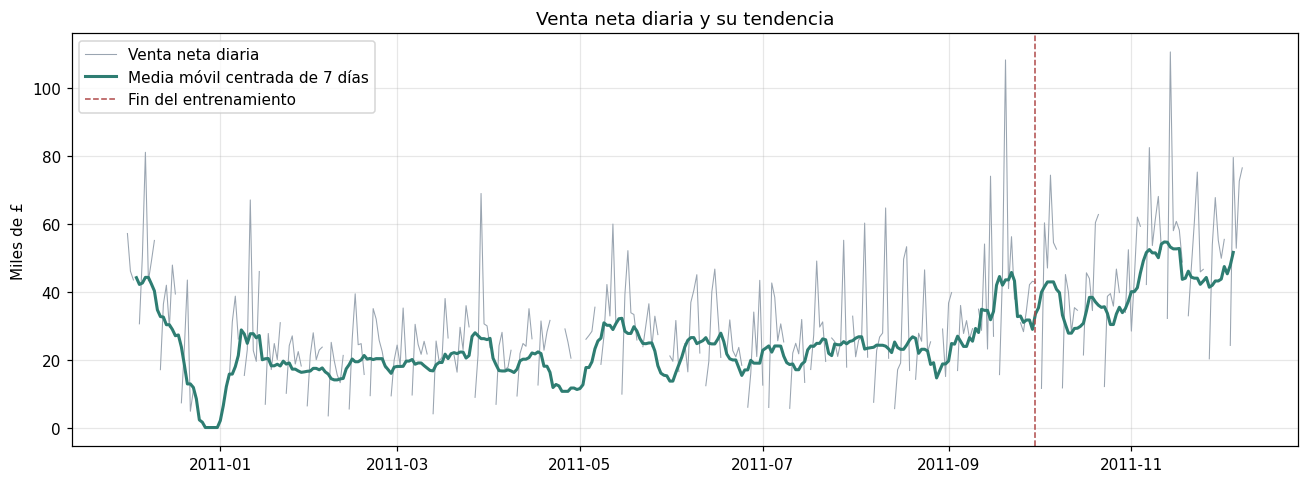

2010-12-01     758.1
2011-01-01     578.9
2011-02-01     499.5
2011-03-01     679.3
2011-04-01     482.1
2011-05-01     731.0
2011-06-01     684.9
2011-07-01     676.8
2011-08-01     701.3
2011-09-01    1011.3
2011-10-01    1061.7
2011-11-01    1427.1
2011-12-01     410.9
Freq: MS, Name: Venta, dtype: float64


In [25]:
y0 = y_cal.fillna(0)
ma7 = y0.rolling(7, center=True).mean()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(cal, y_cal / 1000, lw=0.7, color="#9AA5B1", label="Venta neta diaria")
ax.plot(cal, ma7 / 1000, lw=2, color="#2E7D72", label="Media móvil centrada de 7 días")
ax.axvline(FIN_TRAIN, color="#B04A4A", ls="--", lw=1, label="Fin del entrenamiento")
ax.set_ylabel("Miles de £"); ax.set_title("Venta neta diaria y su tendencia")
ax.legend()
guardar_fig(fig, "p3_tendencia")
plt.show()

mensual = y0.resample("MS").sum()
print((mensual / 1000).round(1))

### 3.2 Índice estacional por día de la semana (solo entrenamiento)

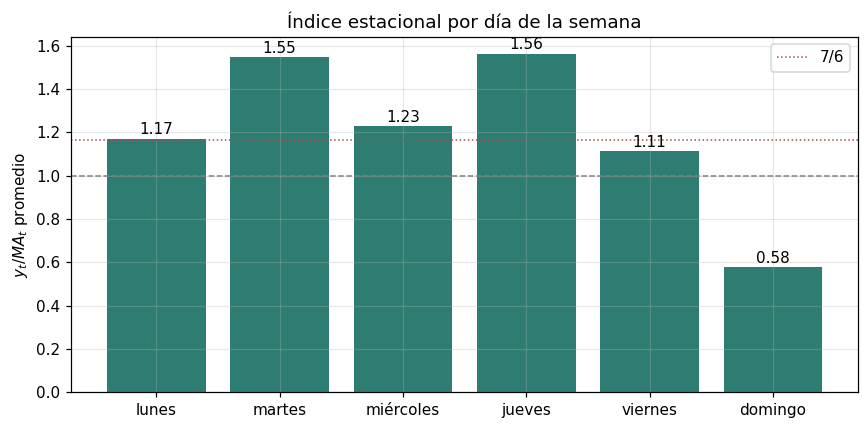

,día,índice,índice sin ventanas con feriados,días
0,lunes,1.171025,1.171025,37
1,martes,1.547940,1.490704,42
2,miércoles,1.229712,1.188999,42
3,jueves,1.563542,1.531593,42
4,viernes,1.114207,1.097096,39
5,domingo,0.576769,0.575350,40


In [26]:
ratio = (y_cal / ma7)[abierto & en_train & (ma7 > 0)]
cerrados_en_ventana = (~abierto).astype(int).rolling(7, center=True).sum()
ratio_limpio = ratio[cerrados_en_ventana.reindex(ratio.index) <= 1]

indice = pd.DataFrame({
    "día": [DIAS_ES[d] for d in sorted(ratio.index.dayofweek.unique())],
    "índice": ratio.groupby(ratio.index.dayofweek).mean().values,
    "índice sin ventanas con feriados": ratio_limpio.groupby(ratio_limpio.index.dayofweek).mean().values,
    "días": ratio.groupby(ratio.index.dayofweek).size().values,
})
guardar_tabla(indice, "p3_indice")
prom_indice = indice["índice"].mean()
cifra("diaMaxIndice", indice.loc[indice["índice"].idxmax(), "día"])
cifra("diaMinIndice", indice.loc[indice["índice"].idxmin(), "día"])
cifra("promIndice", prom_indice, "{:.3f}")
cifra("promIndiceLimpio", indice["índice sin ventanas con feriados"].mean(), "{:.3f}")
for _, f in indice.iterrows():
    cifra("indice" + {"lunes": "Lun", "martes": "Mar", "miércoles": "Mie", "jueves": "Jue",
                      "viernes": "Vie", "domingo": "Dom"}[f["día"]], f["índice"], "{:.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(indice["día"], indice["índice"], color="#2E7D72")
ax.axhline(1, color="gray", ls="--", lw=1)
ax.axhline(7 / 6, color="#B04A4A", ls=":", lw=1, label="7/6")
for i, v in enumerate(indice["índice"]):
    ax.text(i, v + 0.02, f"{v:.2f}", ha="center")
ax.set_ylabel("$y_t / MA_t$ promedio"); ax.set_title("Índice estacional por día de la semana")
ax.legend()
guardar_fig(fig, "p3_indice")
plt.show()
indice

### 3.3 Autocorrelación de los días abiertos del entrenamiento (una fila por día)

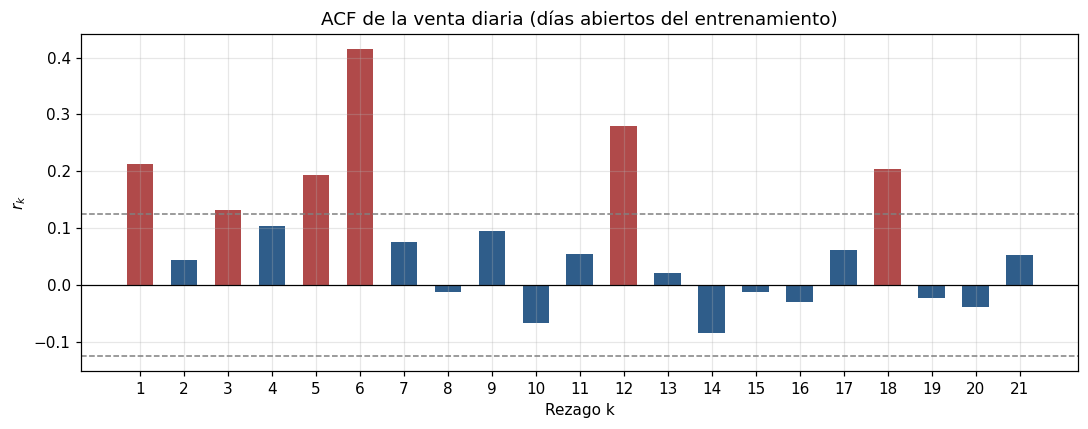

n = 245; bandas ±0.125; rezagos fuera: 6 de 21
r1 = 0.212 -> reprueba la prueba de retardo 1
Pico (sin contar k=1): k = 6, r = 0.414
Q(6) = 71.6 (p = 1.96e-13); Q(12) = 97.6 (p = 1.65e-15)


'245'

In [27]:
y_tr = y_cal[abierto & en_train].values
n_tr = len(y_tr)
r_tr = acf(y_tr, 21)
fig, ax = plt.subplots(figsize=(10, 4))
fuera_33 = graficar_acf(ax, r_tr, n_tr, "ACF de la venta diaria (días abiertos del entrenamiento)")
guardar_fig(fig, "p3_acf")
plt.show()

Q6, p6 = ljung_box(y_tr, 6); Q12, p12 = ljung_box(y_tr, 12)
pico = int(np.argmax(r_tr[1:]) + 2)  # el mayor después del rezago 1
print(f"n = {n_tr}; bandas ±{bandas(n_tr):.3f}; rezagos fuera: {fuera_33} de 21")
print(f"r1 = {r_tr[0]:.3f} -> {'reprueba' if abs(r_tr[0]) > bandas(n_tr) else 'pasa'} la prueba de retardo 1")
print(f"Pico (sin contar k=1): k = {pico}, r = {r_tr[pico - 1]:.3f}")
print(f"Q(6) = {Q6:.1f} (p = {p6:.2e}); Q(12) = {Q12:.1f} (p = {p12:.2e})")
cifra("fueraTres", fuera_33, "{:d}"); cifra("rUnoTres", r_tr[0], "{:.3f}")
cifra("picoTres", pico, "{:d}"); cifra("rPicoTres", r_tr[pico - 1], "{:.3f}")
cifra("QseisTres", Q6, "{:.1f}"); cifra("QdoceTres", Q12, "{:.1f}")
cifra("bandaTres", bandas(n_tr), "{:.3f}")
cifra("pseisTres", p6, "{:.2g}"); cifra("pdoceTres", p12, "{:.2g}"); cifra("nTres", n_tr, "{:d}")

## Parte 4: Del AR(1) al SARIMA
### 4.1 OLS contra indicadoras de día de la semana

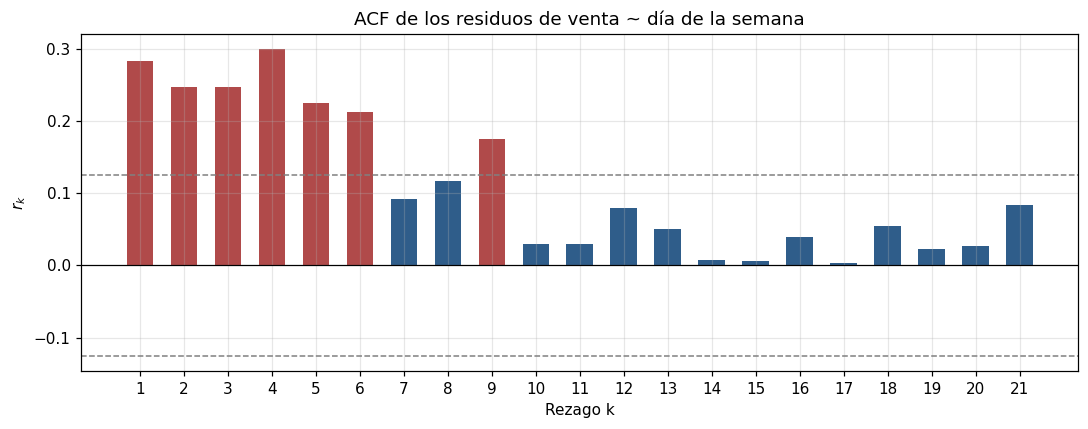

Rezagos fuera: 7; r1 = 0.282, r6 = 0.212, r12 = 0.079, r21 = 0.084


'0.084'

In [28]:
DOWS = sorted(dow[abierto & en_train].unique())   # los seis días que abre la tienda


def indicadoras(d):
    d = np.asarray(d)
    return np.column_stack([(d == k).astype(float) for k in DOWS])


X_dow = indicadoras(dow[abierto & en_train].values)
beta_dow, *_ = np.linalg.lstsq(X_dow, y_tr, rcond=None)
e = y_tr - X_dow @ beta_dow
r_e = acf(e, 21)

fig, ax = plt.subplots(figsize=(10, 4))
fuera_41 = graficar_acf(ax, r_e, len(e), "ACF de los residuos de venta ~ día de la semana")
guardar_fig(fig, "p4_acf_dow")
plt.show()
print(f"Rezagos fuera: {fuera_41}; r1 = {r_e[0]:.3f}, r6 = {r_e[5]:.3f}, r12 = {r_e[11]:.3f}, r21 = {r_e[20]:.3f}")
cifra("fueraCuatroUno", fuera_41, "{:d}"); cifra("rUnoCuatroUno", r_e[0], "{:.3f}")
cifra("rVeintiunoCuatroUno", r_e[20], "{:.3f}")

### 4.2 AR(1) sobre los residuos

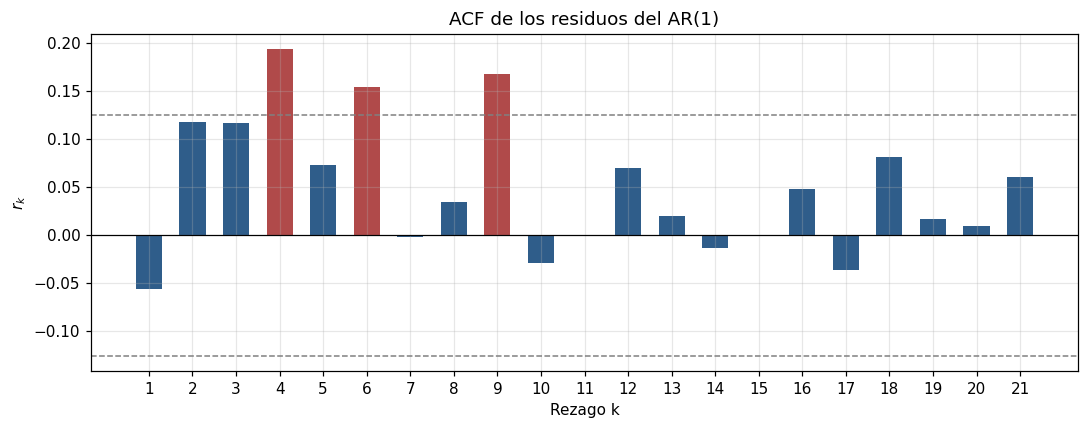

phi = 0.285; rezagos fuera: [4, 6, 9]
Q(6) = 24.3 (p = 0.000194, gl = 5); Q(12) = 33.2 (p = 0.000483, gl = 11)


'0.000483'

In [29]:
c_ar, phi_ar = ar1_ols(e)
u = e[1:] - c_ar - phi_ar * e[:-1]
r_u = acf(u, 21)
fig, ax = plt.subplots(figsize=(10, 4))
fuera_42 = graficar_acf(ax, r_u, len(u), "ACF de los residuos del AR(1)")
guardar_fig(fig, "p4_acf_ar1")
plt.show()
Qu6, pu6 = ljung_box(u, 6, gl_restar=1); Qu12, pu12 = ljung_box(u, 12, gl_restar=1)
rezagos_fuera_42 = [int(k) for k in np.where(np.abs(r_u) > bandas(len(u)))[0] + 1]
print(f"phi = {phi_ar:.3f}; rezagos fuera: {rezagos_fuera_42}")
print(f"Q(6) = {Qu6:.1f} (p = {pu6:.3g}, gl = 5); Q(12) = {Qu12:.1f} (p = {pu12:.3g}, gl = 11)")
cifra("phiAR", phi_ar, "{:.3f}"); cifra("rezagosFueraAR", ", ".join(map(str, rezagos_fuera_42)) or "ninguno")
cifra("QseisAR", Qu6, "{:.1f}"); cifra("pseisAR", pu6, "{:.3g}")
cifra("QdoceAR", Qu12, "{:.1f}"); cifra("pdoceAR", pu12, "{:.3g}")

### 4.3 SARIMA con $s = 6$ sobre el logaritmo

In [30]:
USAR_SARIMA = True
if USAR_SARIMA:
    from statsmodels.tsa.statespace.sarimax import SARIMAX

MODELOS_S = {
    "S1": dict(order=(1, 0, 0), seasonal_order=(1, 0, 0, 6), trend="c"),
    "S2": dict(order=(0, 1, 1), seasonal_order=(0, 1, 1, 6), trend="n"),
}
MAXITER = {}


def ajustar_sarima(nombre, valores_log, maxiter=50):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return SARIMAX(valores_log, **MODELOS_S[nombre]).fit(disp=False, maxiter=maxiter)


assert (y_tr > 0).all(), "Hay días con venta <= 0: el logaritmo no está definido"
log_tr = np.log(y_tr)
res_s, filas = {}, []
if USAR_SARIMA:
    for nombre in MODELOS_S:
        r50 = ajustar_sarima(nombre, log_tr, 50)
        conv = r50.mle_retvals["converged"]
        fila = {"modelo": nombre, "convergió (maxiter=50)": "sí" if conv else "no",
                "parámetros (50)": ", ".join(f"{k}={v:.4f}" for k, v in zip(r50.param_names, r50.params))}
        if conv:
            res_s[nombre], MAXITER[nombre] = r50, 50
            fila["convergió (maxiter=500)"], fila["parámetros (500)"] = "--", "--"
        else:
            r500 = ajustar_sarima(nombre, log_tr, 500)
            res_s[nombre], MAXITER[nombre] = r500, 500
            fila["convergió (maxiter=500)"] = "sí" if r500.mle_retvals["converged"] else "no"
            fila["parámetros (500)"] = ", ".join(f"{k}={v:.4f}" for k, v in zip(r500.param_names, r500.params))
        fila["AIC"] = res_s[nombre].aic
        filas.append(fila)
    tabla_43 = pd.DataFrame(filas)
    guardar_tabla(tabla_43, "p4_sarima", formatos={"AIC": "{:.1f}"})
    for nombre in res_s:
        print(nombre, "\n", res_s[nombre].summary().tables[1])
    tabla_43

S1 
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      4.2709      0.510      8.382      0.000       3.272       5.270
ar.L1          0.1277      0.068      1.889      0.059      -0.005       0.260
ar.S.L6        0.5165      0.048     10.747      0.000       0.422       0.611
sigma2         0.2189      0.017     13.132      0.000       0.186       0.252
S2 
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.9091      0.034    -26.868      0.000      -0.975      -0.843
ma.S.L6       -0.6836      0.051    -13.450      0.000      -0.783      -0.584
sigma2         0.2139      0.016     13.510      0.000       0.183       0.245


### 4.4 Diagnóstico de residuos

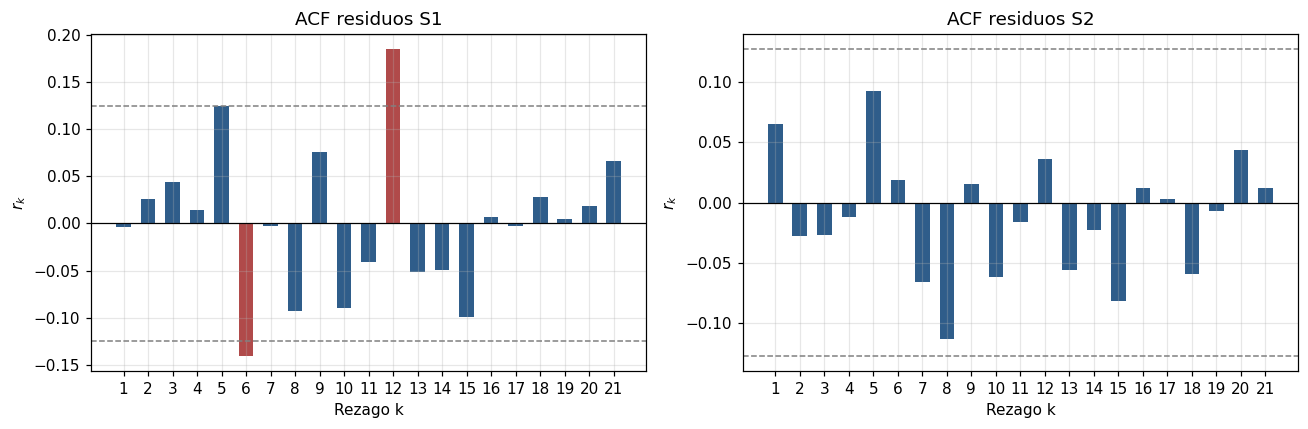

In [31]:
if USAR_SARIMA:
    filas = []
    for nombre, descartar in [("S1", 0), ("S2", 7)]:
        resid = res_s[nombre].resid[descartar:]
        q6, pp6 = ljung_box(resid, 6, gl_restar=2)
        q12, pp12 = ljung_box(resid, 12, gl_restar=2)
        filas.append({"modelo": nombre, "residuos descartados": descartar,
                      "Q(6)": q6, "p (gl=4)": pp6, "Q(12)": q12, "p (gl=10)": pp12})
        cifra(f"Qseis{nombre}", q6, "{:.1f}"); cifra(f"pseis{nombre}", pp6, "{:.3g}")
        cifra(f"Qdoce{nombre}", q12, "{:.1f}"); cifra(f"pdoce{nombre}", pp12, "{:.3g}")
        cifra(f"ruidoBlanco{nombre}", "sí" if min(pp6, pp12) > 0.05 else "no")
    tabla_44 = pd.DataFrame(filas)
    guardar_tabla(tabla_44, "p4_diagnostico", formatos={"p (gl=4)": "{:.3g}", "p (gl=10)": "{:.3g}"})

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    graficar_acf(axes[0], acf(res_s["S1"].resid, 21), len(log_tr), "ACF residuos S1")
    graficar_acf(axes[1], acf(res_s["S2"].resid[7:], 21), len(log_tr) - 7, "ACF residuos S2")
    guardar_fig(fig, "p4_acf_sarima")
    plt.show()
    tabla_44

### 4.5 ¿Hacia dónde van los pronósticos a horizonte largo?

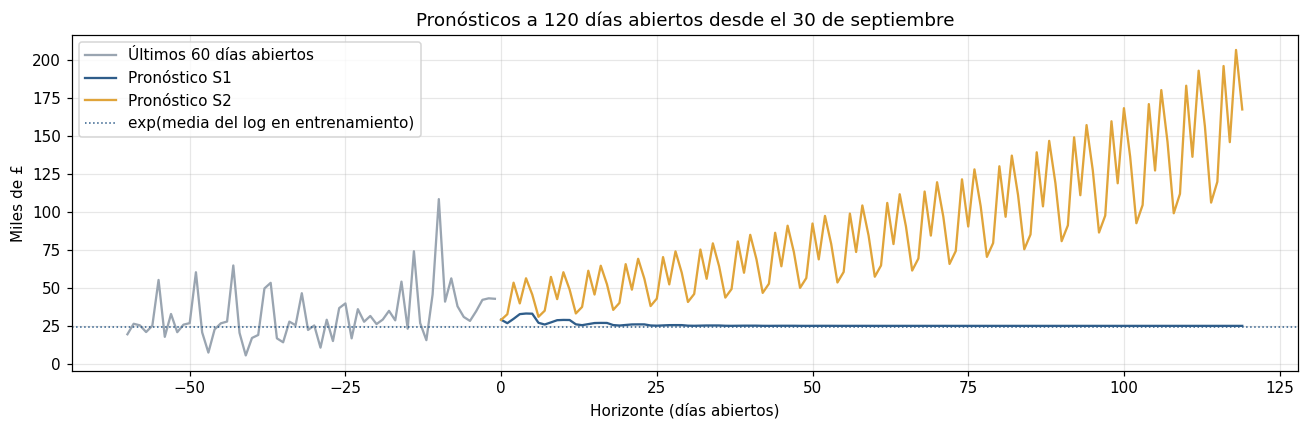

In [32]:
if USAR_SARIMA:
    H = 120
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(np.arange(-60, 0), y_tr[-60:] / 1000, color="#9AA5B1", label="Últimos 60 días abiertos")
    for nombre, color in [("S1", "#2F5D8A"), ("S2", "#E0A43A")]:
        ax.plot(np.arange(H), np.exp(res_s[nombre].forecast(H)) / 1000, color=color, label=f"Pronóstico {nombre}")
    ax.axhline(np.exp(log_tr.mean()) / 1000, color="#2F5D8A", ls=":", lw=1,
               label="exp(media del log en entrenamiento)")
    ax.set_xlabel("Horizonte (días abiertos)"); ax.set_ylabel("Miles de £")
    ax.set_title("Pronósticos a 120 días abiertos desde el 30 de septiembre")
    ax.legend()
    guardar_fig(fig, "p4_horizonte")
    plt.show()

## Parte 5: Pronóstico y fuga
Tabla de trabajo: una fila por día del calendario con la venta, el día de la semana,
un índice de tiempo y los rezagos $y_{t-7}$ y $y_{t-14}$ de M2.
$y_{t-7}$ es el valor del mismo día de la semana abierto más reciente en o antes de $t-7$;
$y_{t-14}$ es el del mismo día de la semana abierto inmediatamente anterior a ese.

In [33]:
dias = pd.DataFrame({"y": y_cal, "dow": dow, "t": np.arange(len(cal), dtype=float), "abierto": abierto})
dias["lag7"] = np.nan
dias["lag14"] = np.nan
for w in DOWS:
    sub = dias[dias["dow"] == w]
    abiertos_w = sub[sub["abierto"]]
    for d in sub.index:
        previos = abiertos_w[abiertos_w.index <= d - pd.Timedelta(days=7)]
        if len(previos) >= 1:
            dias.loc[d, "lag7"] = previos["y"].iloc[-1]
        if len(previos) >= 2:
            dias.loc[d, "lag14"] = previos["y"].iloc[-2]
dias["ma7"] = ma7          # solo para la trampa de 5.4

print(dias.loc["2011-05-09", ["y", "lag7", "lag14"]])
print("y del 18 de abril:", dias.loc["2011-04-18", "y"])

y        26878.48
lag7     31388.85
lag14    21789.52
Name: 2011-05-09 00:00:00, dtype: object
y del 18 de abril: 31388.85


### 5.1 Los modelos

In [34]:
def ols(X, y):
    b, *_ = np.linalg.lstsq(X, y, rcond=None)
    return b


def X_m1(df):
    return np.column_stack([df["t"].values, indicadoras(df["dow"].values)])


def X_m2(df, con_ma=False):
    cols = [indicadoras(df["dow"].values), df["lag7"].values, df["lag14"].values]
    if con_ma:
        cols.append(df["ma7"].values)
    return np.column_stack(cols)


def pron_B1(hist, obj):
    return np.full(len(obj), hist["y"].mean())


def pron_B2(hist, obj):
    return np.array([hist.loc[hist["dow"] == w, "y"].iloc[-1] for w in obj["dow"]])


def pron_M1(hist, obj):
    return X_m1(obj) @ ols(X_m1(hist), hist["y"].values)


def pron_M2(hist, obj, con_ma=False):
    h = hist.dropna(subset=["lag7", "lag14"] + (["ma7"] if con_ma else []))
    return X_m2(obj, con_ma) @ ols(X_m2(h, con_ma), h["y"].values)


CONVERGENCIA = []


def pron_S(nombre):
    def f(hist, obj):
        res = ajustar_sarima(nombre, np.log(hist["y"].values), MAXITER[nombre])
        CONVERGENCIA.append((nombre, hist.index[-1], res.mle_retvals["converged"]))
        return np.exp(res.forecast(len(obj)))   # el horizonte = posición entre los días abiertos
    return f


MODELOS = {"B1": pron_B1, "B2": pron_B2, "M1": pron_M1, "M2": pron_M2}
if USAR_SARIMA:
    MODELOS.update({"S1": pron_S("S1"), "S2": pron_S("S2")})

### 5.2 Tres formas de estimar el error
(b) y (c): origen móvil semanal. (a): validación cruzada aleatoria de 5 folds, 10 semillas.

In [35]:
abiertos_df = dias[dias["abierto"]]


def origen_movil(modelo, origenes, ultimo_eval):
    reales, preds, fechas = [], [], []
    for o in origenes:
        hist = abiertos_df[abiertos_df.index <= o]
        obj = abiertos_df[(abiertos_df.index > o) & (abiertos_df.index <= o + pd.Timedelta(days=7))
                          & (abiertos_df.index <= ultimo_eval)]
        if len(obj) == 0:
            continue
        preds.append(modelo(hist, obj)); reales.append(obj["y"].values); fechas.append(obj.index)
    return np.concatenate(reales), np.concatenate(preds), np.concatenate(fechas)


def errores(real, pred):
    err = real - pred
    return np.mean(np.abs(err)), np.sqrt(np.mean(err ** 2))


ORIG_B = pd.date_range("2011-05-01", FIN_TRAIN, freq="W-SUN")
ORIG_C = pd.date_range("2011-10-02", FIN - pd.Timedelta(days=1), freq="W-SUN")
print(f"Orígenes (b): {ORIG_B[0].date()} a {ORIG_B[-1].date()} ({len(ORIG_B)}); "
      f"(c): {ORIG_C[0].date()} a {ORIG_C[-1].date()} ({len(ORIG_C)})")

train_df = abiertos_df[abiertos_df.index <= FIN_TRAIN]


def cv_aleatoria(nombre, con_ma=False, k=5, semillas=range(10)):
    if nombre == "B1":
        df, f = train_df, lambda tr, te: pron_B1(tr, te)
    elif nombre == "M1":
        df, f = train_df, pron_M1
    else:
        df = train_df.dropna(subset=["lag7", "lag14"] + (["ma7"] if con_ma else []))
        f = lambda tr, te: pron_M2(tr, te, con_ma)
    maes, rmses = [], []
    for s in semillas:
        perm = np.random.default_rng(s).permutation(len(df))
        folds = np.array_split(perm, k)
        real, pred = [], []
        for idx in folds:
            te = df.iloc[np.sort(idx)]
            tr = df.drop(te.index)
            real.append(te["y"].values); pred.append(f(tr, te))
        mae, rmse = errores(np.concatenate(real), np.concatenate(pred))
        maes.append(mae); rmses.append(rmse)
    return np.mean(maes), np.std(maes, ddof=1), np.mean(rmses), np.std(rmses, ddof=1)


resultados, pron_prueba = [], {}
for nombre, modelo in MODELOS.items():
    fila = {"modelo": nombre}
    if nombre in ("B1", "M1", "M2"):
        m, sm_, r, sr = cv_aleatoria(nombre)
        fila["(a) MAE"], fila["(a) RMSE"] = f"{m:,.0f} ± {sm_:,.0f}", f"{r:,.0f} ± {sr:,.0f}"
    else:
        fila["(a) MAE"] = fila["(a) RMSE"] = "no aplica"
    real_b, pred_b, _ = origen_movil(modelo, ORIG_B, FIN_TRAIN)
    fila["(b) MAE"], fila["(b) RMSE"] = errores(real_b, pred_b)
    real_c, pred_c, fechas_c = origen_movil(modelo, ORIG_C, FIN)
    fila["(c) MAE"], fila["(c) RMSE"] = errores(real_c, pred_c)
    pron_prueba[nombre] = pd.Series(pred_c, index=fechas_c)
    resultados.append(fila)
    print(fila)

tabla_52 = pd.DataFrame(resultados)
fmt = {c: "{:,.0f}" for c in ["(b) MAE", "(b) RMSE", "(c) MAE", "(c) RMSE"]}
guardar_tabla(tabla_52, "p5_errores", formatos=fmt)
real_prueba = pd.Series(real_c, index=fechas_c)
ganador = tabla_52.loc[tabla_52["(c) MAE"].idxmin(), "modelo"]
cifra("ganadorPrueba", ganador)
t52 = tabla_52.set_index("modelo")
for m_ in ["B1", "M1", "M2"]:
    a_mae = float(t52.loc[m_, "(a) MAE"].split(" ")[0].replace(",", ""))
    cifra(f"maeA{m_}", a_mae, "{:,.0f}")
    cifra(f"masCerca{m_}", "(a)" if abs(a_mae - t52.loc[m_, "(c) MAE"]) < abs(t52.loc[m_, "(b) MAE"] - t52.loc[m_, "(c) MAE"]) else "(b)")
for _, f in tabla_52.iterrows():
    cifra(f"maeC{f['modelo']}", f["(c) MAE"], "{:,.0f}")
    cifra(f"maeB{f['modelo']}", f["(b) MAE"], "{:,.0f}")
if CONVERGENCIA:
    conv = pd.DataFrame(CONVERGENCIA, columns=["modelo", "origen", "convergió"])
    print(conv.groupby("modelo")["convergió"].agg(["sum", "size"]))
    cifra("noConvergio", int((~conv["convergió"]).sum()), "{:d}")
tabla_52

Orígenes (b): 2011-05-01 a 2011-09-25 (22); (c): 2011-10-02 a 2011-12-04 (10)
{'modelo': 'B1', '(a) MAE': '10,243 ± 37', '(a) RMSE': '14,214 ± 47', '(b) MAE': np.float64(10227.725567522542), '(b) RMSE': np.float64(14884.076489750792), '(c) MAE': np.float64(22404.245040329886), '(c) RMSE': np.float64(26928.109005379512)}
{'modelo': 'B2', '(a) MAE': 'no aplica', '(a) RMSE': 'no aplica', '(b) MAE': np.float64(11262.048734375001), '(b) RMSE': np.float64(15568.72331149482), '(c) MAE': np.float64(14147.203965517241), '(c) RMSE': np.float64(18373.551546664)}
{'modelo': 'M1', '(a) MAE': '9,165 ± 108', '(a) RMSE': '12,582 ± 158', '(b) MAE': np.float64(9760.977850707864), '(b) RMSE': np.float64(13822.418375769068), '(c) MAE': np.float64(15177.089926477456), '(c) RMSE': np.float64(20149.464585232443)}
{'modelo': 'M2', '(a) MAE': '8,292 ± 169', '(a) RMSE': '11,724 ± 224', '(b) MAE': np.float64(9229.227237144018), '(b) RMSE': np.float64(13378.323080466898), '(c) MAE': np.float64(15156.973307747881)

,modelo,(a) MAE,(a) RMSE,(b) MAE,(b) RMSE,(c) MAE,(c) RMSE
0,B1,"10,243 ± 37","14,214 ± 47",10227.725568,14884.076490,22404.245040,26928.109005
1,B2,no aplica,no aplica,11262.048734,15568.723311,14147.203966,18373.551547
2,M1,"9,165 ± 108","12,582 ± 158",9760.977851,13822.418376,15177.089926,20149.464585
3,M2,"8,292 ± 169","11,724 ± 224",9229.227237,13378.323080,15156.973308,19733.979696
4,S1,no aplica,no aplica,9720.935592,13736.993271,16703.498708,20934.572057
5,S2,no aplica,no aplica,10031.503003,13959.601095,12355.694563,15696.087428


### 5.3 Pronósticos contra la serie real en el período de prueba

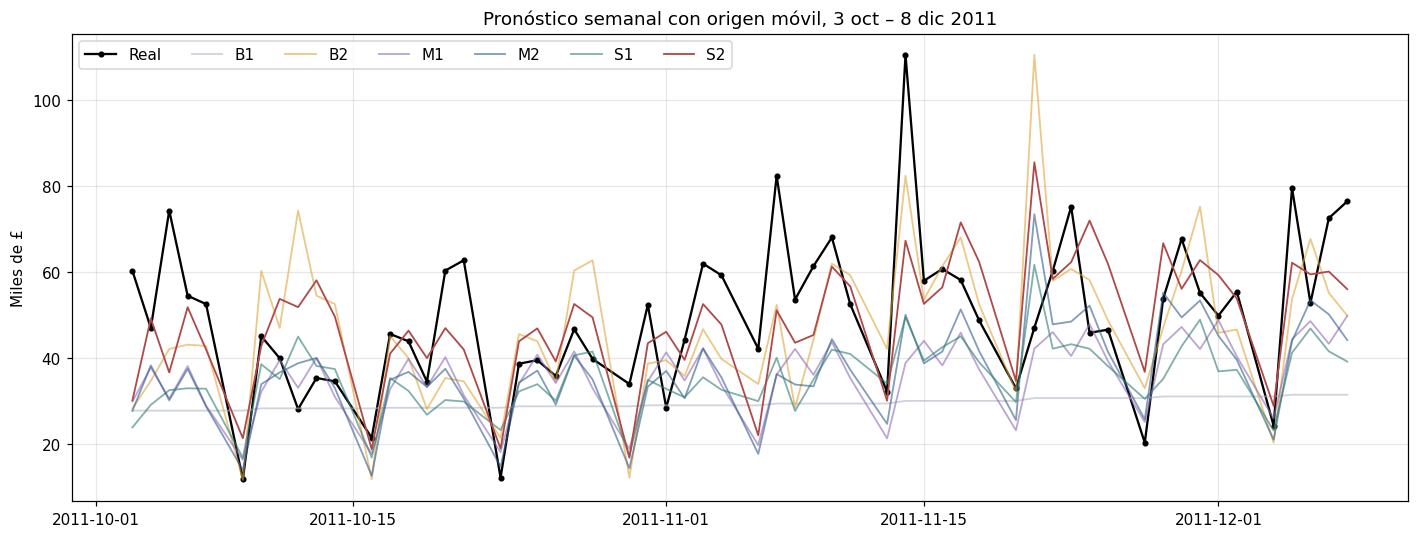

In [36]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(real_prueba.index, real_prueba / 1000, "o-", color="black", lw=1.5, ms=3, label="Real")
colores = {"B1": "#B0B7C3", "B2": "#E0A43A", "M1": "#8E6BB8", "M2": "#2F5D8A", "S1": "#2E7D72", "S2": "#B04A4A"}
for nombre, s in pron_prueba.items():
    ax.plot(s.index, s / 1000, lw=1.2, color=colores[nombre], label=nombre,
            alpha=1 if nombre == ganador else 0.6)
ax.set_ylabel("Miles de £"); ax.set_title("Pronóstico semanal con origen móvil, 3 oct – 8 dic 2011")
ax.legend(ncol=7, loc="upper left")
guardar_fig(fig, "p5_prueba")
plt.show()

### 5.4 La trampa: agregar a M2 la media móvil centrada de 7 días

In [37]:
m, s_, r, sr = cv_aleatoria("M2", con_ma=True)
real_b, pred_b, _ = origen_movil(lambda h, o: pron_M2(h, o, con_ma=True), ORIG_B, FIN_TRAIN)
mae_b, rmse_b = errores(real_b, pred_b)
fila_m2 = tabla_52.set_index("modelo").loc["M2"]
tabla_54 = pd.DataFrame([
    {"modelo": "M2", "(a) MAE": fila_m2["(a) MAE"], "(a) RMSE": fila_m2["(a) RMSE"],
     "(b) MAE": fila_m2["(b) MAE"], "(b) RMSE": fila_m2["(b) RMSE"]},
    {"modelo": "M2 + MA7 centrada", "(a) MAE": f"{m:,.0f} ± {s_:,.0f}", "(a) RMSE": f"{r:,.0f} ± {sr:,.0f}",
     "(b) MAE": mae_b, "(b) RMSE": rmse_b},
])
guardar_tabla(tabla_54, "p5_trampa", formatos={"(b) MAE": "{:,.0f}", "(b) RMSE": "{:,.0f}"})
cifra("maeBTrampa", mae_b, "{:,.0f}")
tabla_54

,modelo,(a) MAE,(a) RMSE,(b) MAE,(b) RMSE
0,M2,"8,292 ± 169","11,724 ± 224",9229.227237,13378.323080
1,M2 + MA7 centrada,"7,425 ± 118","10,059 ± 189",8252.009712,11276.059708


## Parte 6: Detrás de la serie hay clientes: RFM
### 6.1 R, F y M al 1 de octubre de 2011

In [38]:
CORTE = pd.Timestamp("2011-10-01")
clientes_df = limpio[limpio["CustomerID"].notna()].copy()
antes = clientes_df[clientes_df["Fecha"] < CORTE]
ventas_antes = antes[~antes["EsCancelacion"]]

rfm = pd.DataFrame({
    "R": (CORTE - ventas_antes.groupby("CustomerID")["Fecha"].max()).dt.days,
    "F": ventas_antes.groupby("CustomerID")["InvoiceNo"].nunique(),
})
rfm["M"] = antes.groupby("CustomerID")["Venta"].sum().reindex(rfm.index)
solo_canc = set(antes["CustomerID"]) - set(rfm.index)
print(f"Clientes con al menos una factura de venta antes del 1 de octubre: {len(rfm):,}")
print(f"Clientes con solo cancelaciones antes del corte (se excluyen): {len(solo_canc)}")
print(f"Clientes con M <= 0: {(rfm['M'] <= 0).sum()}")
cifra("nClientesRFM", len(rfm), "{:,}"); cifra("nMcero", int((rfm["M"] <= 0).sum()), "{:d}")
cifra("nSoloCanc", len(solo_canc), "{:d}")
guardar_tabla(rfm.describe().T.reset_index().rename(columns={"index": "variable"}), "p6_describe",
              formatos={c: "{:,.1f}" for c in ["mean", "std", "min", "25%", "50%", "75%", "max"]} | {"count": "{:,.0f}"})
rfm[rfm["M"] <= 0].head(10)

Clientes con al menos una factura de venta antes del 1 de octubre: 3,613
Clientes con solo cancelaciones antes del corte (se excluyen): 35
Clientes con M <= 0: 7


,R,F,M
CustomerID,,,
12346,256,1,0.00
13672,232,2,0.00
14205,195,1,-15.30
16546,221,2,-95.93
17190,138,1,0.00
17548,164,1,-141.48
18268,65,1,0.00


### 6.2 Puntajes por quintiles

In [39]:
print("Distribución de F:", rfm["F"].value_counts().sort_index().head(8).to_dict())
try:
    pd.qcut(rfm["F"], 5, labels=False)
    print("qcut sobre F crudo funcionó")
except ValueError as err:
    print("qcut sobre F crudo falla:", err)
cifra("pctFuno", 100 * (rfm["F"] == 1).mean(), "{:.1f}%")

orden = rfm.sort_index()                                    # CustomerID ascendente
barajado = orden.iloc[np.random.default_rng(2026).permutation(len(orden))]
etq = [1, 2, 3, 4, 5]
barajado["pR"] = pd.qcut((-barajado["R"]).rank(method="first"), 5, labels=etq).astype(int)
barajado["pF"] = pd.qcut(barajado["F"].rank(method="first"), 5, labels=etq).astype(int)
barajado["pM"] = pd.qcut(barajado["M"].rank(method="first"), 5, labels=etq).astype(int)
rfm = barajado.sort_index()
rfm["suma"] = rfm[["pR", "pF", "pM"]].sum(axis=1)
empates = rfm.groupby("F")["pF"].nunique()
print("Valores de F que quedaron repartidos en más de un puntaje:", empates[empates > 1].to_dict())

Distribución de F: {1: 1453, 2: 691, 3: 442, 4: 278, 5: 176, 6: 120, 7: 88, 8: 72}
qcut sobre F crudo falla: Bin edges must be unique: Index([1.0, 1.0, 1.0, 3.0, 5.0, 138.0], dtype='float64', name='F').
You can drop duplicate edges by setting the 'duplicates' kwarg
Valores de F que quedaron repartidos en más de un puntaje: {1: 3, 3: 2, 5: 2}


/tmp/ipykernel_8364/1510641491.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  barajado["pR"] = pd.qcut((-barajado["R"]).rank(method="first"), 5, labels=etq).astype(int)
/tmp/ipykernel_8364/1510641491.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  barajado["pF"] = pd.qcut(barajado["F"].rank(method="first"), 5, labels=etq).astype(int)
/tmp/ipykernel_8364/1510641491.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_inde

### 6.3 ¿Qué dimensión anticipa quién vuelve a comprar?

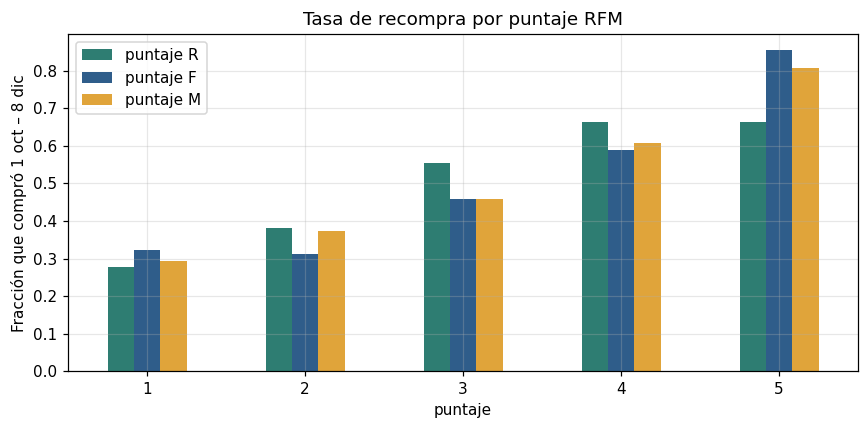

(         puntaje R  puntaje F  puntaje M
 puntaje                                 
 1         0.278008   0.323651   0.294606
 2         0.380886   0.313019   0.372576
 3         0.553250   0.457815   0.457815
 4         0.664820   0.590028   0.606648
 5         0.662517   0.854772   0.807746,
           clasificador       AUC
 0  R (signo invertido)  0.672615
 1                    F  0.720491
 2                    M  0.708914
 3         pR + pF + pM  0.734231)

In [40]:
from sklearn.metrics import roc_auc_score

despues = clientes_df[(clientes_df["Fecha"] >= CORTE) & (clientes_df["Fecha"] <= FIN)]
compradores = set(despues.loc[~despues["EsCancelacion"], "CustomerID"])
rfm["compra"] = rfm.index.isin(compradores).astype(int)
tasa = pd.DataFrame({f"puntaje {d}": rfm.groupby(f"p{d}")["compra"].mean() for d in "RFM"})
tasa.index.name = "puntaje"
guardar_tabla(tasa, "p6_tasa_compra", index=True, formatos={c: "{:.3f}" for c in tasa.columns})
auc = pd.DataFrame({"clasificador": ["R (signo invertido)", "F", "M", "pR + pF + pM"],
                    "AUC": [roc_auc_score(rfm["compra"], -rfm["R"]), roc_auc_score(rfm["compra"], rfm["F"]),
                            roc_auc_score(rfm["compra"], rfm["M"]), roc_auc_score(rfm["compra"], rfm["suma"])]})
guardar_tabla(auc, "p6_auc", formatos={"AUC": "{:.3f}"})
cifra("tasaCompra", 100 * rfm["compra"].mean(), "{:.1f}%")
cifra("mejorDim", ["R", "F", "M"][int(np.argmax(auc["AUC"].values[:3]))])
for tag, v in zip(["R", "F", "M", "Suma"], auc["AUC"]):
    cifra(f"auc{tag}", v, "{:.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
tasa.plot(kind="bar", ax=ax, color=["#2E7D72", "#2F5D8A", "#E0A43A"], rot=0)
ax.set_ylabel("Fracción que compró 1 oct – 8 dic"); ax.set_title("Tasa de recompra por puntaje RFM")
guardar_fig(fig, "p6_tasa_compra")
plt.show()
tasa, auc

### 6.4 Campeones y 6.5 clientes nuevos

In [41]:
venta_post = despues.groupby("CustomerID")["Venta"].sum()
total_post = venta_post.sum()
campeones = rfm[(rfm[["pR", "pF", "pM"]] >= 4).all(axis=1)].index
nuevos = venta_post.index.difference(rfm.index)
frac_camp = len(campeones) / len(rfm)
share_camp = venta_post.reindex(campeones).fillna(0).sum() / total_post
share_nuevos = venta_post.reindex(nuevos).sum() / total_post
print(f"Campeones: {len(campeones):,} ({frac_camp:.1%} de los clientes); "
      f"generaron {share_camp:.1%} de la venta neta 1 oct – 8 dic (£{total_post:,.0f})")
print(f"Clientes nuevos en el período: {len(nuevos):,}; generaron {share_nuevos:.1%} de la venta neta")
cifra("nCampeones", len(campeones), "{:,}"); cifra("fracCampeones", 100 * frac_camp, "{:.1f}%")
cifra("shareCampeones", 100 * share_camp, "{:.1f}%"); cifra("totalPost", total_post, "£{:,.0f}")
cifra("nNuevos", len(nuevos), "{:,}"); cifra("shareNuevos", 100 * share_nuevos, "{:.1f}%")

tabla_6 = pd.DataFrame({
    "grupo": ["Campeones", "Resto de clientes existentes", "Clientes nuevos"],
    "clientes": [len(campeones), len(rfm) - len(campeones), len(nuevos)],
    "venta neta 1 oct–8 dic (£)": [venta_post.reindex(campeones).fillna(0).sum(),
                                   venta_post.reindex(rfm.index.difference(campeones)).fillna(0).sum(),
                                   venta_post.reindex(nuevos).sum()],
})
tabla_6["% de la venta"] = 100 * tabla_6["venta neta 1 oct–8 dic (£)"] / total_post
guardar_tabla(tabla_6, "p6_grupos", formatos={"venta neta 1 oct–8 dic (£)": "{:,.0f}", "% de la venta": "{:.1f}"})
escribir_cifras()
tabla_6

Campeones: 781 (21.6% de los clientes); generaron 53.2% de la venta neta 1 oct – 8 dic (£2,396,690)
Clientes nuevos en el período: 723; generaron 15.8% de la venta neta


,grupo,clientes,venta neta 1 oct–8 dic (£),% de la venta
0,Campeones,781,1275403.16,53.215183
1,Resto de clientes existentes,2832,743053.96,31.003336
2,Clientes nuevos,723,378233.23,15.781481


In [42]:
!pip install -q uv
!uv lock
!zip -r resultados.zip figuras tablas uv.lock
from google.colab import files
files.download("resultados.zip")

Using CPython 3.13.18 interpreter at: /usr/bin/python3
Resolved 116 packages in 1.05s
  adding: figuras/ (stored 0%)
  adding: figuras/p4_horizonte.png (deflated 6%)
  adding: figuras/p3_tendencia.png (deflated 4%)
  adding: figuras/p5_prueba.png (deflated 2%)
  adding: figuras/p3_indice.png (deflated 16%)
  adding: figuras/p6_tasa_compra.png (deflated 19%)
  adding: figuras/p0_dos_razones.png (deflated 6%)
  adding: figuras/p4_acf_dow.png (deflated 22%)
  adding: figuras/p4_acf_ar1.png (deflated 23%)
  adding: figuras/p0_realizaciones.png (deflated 4%)
  adding: figuras/p4_acf_sarima.png (deflated 24%)
  adding: figuras/p3_acf.png (deflated 22%)
  adding: tablas/ (stored 0%)
  adding: tablas/cifras.tex (deflated 81%)
  adding: tablas/p5_errores.tex (deflated 50%)
  adding: tablas/p5_trampa.tex (deflated 30%)
  adding: tablas/p1_prefijos.tex (deflated 28%)
  adding: tablas/p6_tasa_compra.tex (deflated 46%)
  adding: tablas/p1_codigos.tex (deflated 63%)
  adding: tablas/p6_grupos.tex (d

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>